# Gradient boosting on the validation years

One `HistGradientBoostingRegressor` per lead time, fitted on the training years (2000-2019) and scored on 2020-2022 against the simple forecasts. Each model predicts how far the high h days ahead will be from that station's usual high on that date (the climatology from `scoring.py`), and the usual high is added back, so the trees don't have to learn the seasons.

Steps:
1. Build the random forest notebook's features, minus the day of year.
2. Tune on validation MAE at leads 1 and 7.
3. Refit the winning setting for each lead and score leads 1 to 7 against the simple forecasts.
4. Test whether the gain over damped anomaly is bigger than luck.
5. Check why the day of year is left out.

In [1]:
import sys
sys.path.insert(0, "../data_scripts")  # relative to the working directory, which Jupyter sets to the notebook's folder

import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor
from prepare_data import STATIONS, load_data
from scoring import LEADS, climatology, simple_forecasts, score

In [2]:
data = load_data()
usual = climatology(data)  # fitted on training years only
# Test years are never touched here.
keep = data.usable & data.period.isin(["train", "validation"])
print(f"{keep.sum():,} train and validation rows")

2,108,345 train and validation rows


## Features

The random forest notebook's features (Danylo's `random_forest.ipynb`) minus the day of year, so both models see the same inputs apart from that. Every feature uses only data through the forecast day t:

* **The station's recent days:** TMAX today and 1-6 days back, its change since yesterday, its 7- and 30-day means, and TMIN today and yesterday.
* **Departure from normal:** the usual high today and on the target day, today's anomaly, and its 3- and 7-day means.
* **Other weather:** precipitation today and over 7 days, snow depth, and average wind (only some stations report it).
* **Neighbours:** today's mean anomaly at the 5 nearest stations, at stations to the west and to the north within 500 km, and across all stations, plus the statewide change since yesterday.
* **Place:** latitude, longitude, elevation.

No day of year: it lets the trees memorize past dates (see the check at the end).

In [3]:
stations = pd.read_csv(STATIONS).set_index("ID")
clim_today = usual(data.STATION, data.DATE)
anomaly = data.TMAX - clim_today
g = data.groupby("STATION", sort=False)
roll = lambda s, n, k, how="mean": s.groupby(data.STATION, sort=False).transform(lambda x: getattr(x.rolling(n, min_periods=k), how)())

F = pd.DataFrame(index=data.index)
F["tmax"] = data.TMAX
for k in range(1, 7):
    F[f"tmax_lag{k}"] = g.TMAX.shift(k)
F["tmax_change1"] = data.TMAX - F.tmax_lag1
F["tmax_mean7"] = roll(data.TMAX, 7, 4)
F["tmax_mean30"] = roll(data.TMAX, 30, 20)
F["tmin"] = data.TMIN
F["tmin_lag1"] = g.TMIN.shift(1)
F["clim_today"] = clim_today
F["anom"] = anomaly
F["anom_mean3"] = roll(anomaly, 3, 2)
F["anom_mean7"] = roll(anomaly, 7, 4)
F["prcp"] = data.PRCP
F["prcp_sum7"] = roll(data.PRCP, 7, 4, "sum")
F["snwd"] = data.SNWD
F["awnd"] = data.AWND

# Neighbours: a date x station table of today's anomaly, averaged over each station's neighbours.
A = anomaly.groupby([data.DATE, data.STATION]).first().unstack()
loc = stations.loc[A.columns]
lat, lon = loc.LATITUDE.to_numpy(), loc.LONGITUDE.to_numpy()
la, lo = np.radians(lat), np.radians(lon)
hav = (np.sin((la[:, None] - la[None, :]) / 2) ** 2
       + np.cos(la[:, None]) * np.cos(la[None, :]) * np.sin((lo[:, None] - lo[None, :]) / 2) ** 2)
dist = 2 * 6371 * np.arcsin(np.sqrt(hav))  # km
np.fill_diagonal(dist, np.inf)
nearest = np.zeros_like(dist)
nearest[np.arange(len(dist))[:, None], np.argsort(dist, axis=1)[:, :5]] = 1
west = ((lon[None, :] < lon[:, None] - 1) & (dist < 500)).astype(float)  # row: station, column: its neighbours
north = ((lat[None, :] > lat[:, None] + 1) & (dist < 500)).astype(float)
values, seen = A.fillna(0).to_numpy(), A.notna().to_numpy().astype(float)
rows_date, rows_station = A.index.get_indexer(data.DATE), A.columns.get_indexer(data.STATION)
with np.errstate(invalid="ignore", divide="ignore"):  # no neighbour reported that day: NaN
    for name, W in [("nbr5_anom", nearest), ("west_anom", west), ("north_anom", north)]:
        F[name] = ((values @ W.T) / (seen @ W.T))[rows_date, rows_station]
state = A.mean(axis=1)
F["state_anom"] = state.to_numpy()[rows_date]
F["state_anom_change1"] = state.diff().to_numpy()[rows_date]

F["latitude"] = data.STATION.map(stations.LATITUDE).to_numpy()
F["longitude"] = data.STATION.map(stations.LONGITUDE).to_numpy()
F["elevation"] = data.STATION.map(stations.ELEVATION).to_numpy()
X = F[keep].astype("float32")

is_train = (data.period[keep] == "train").to_numpy()
train, rows = data[keep][is_train], data[keep][~is_train]
print(X.shape)

(2108345, 28)


## Tuning

Each setting is trained on all training rows and scored on the validation rows at leads 1 and 7 (the easiest and hardest lead), the same test as the random forest's tuning. The lowest mean MAE over the two wins. The search goes in stages, keeping the best setting from each:

1. Loss: squared error (the untuned model) vs absolute error, which targets MAE directly
2. Learning rate (0.05, 0.1, 0.2) x leaves per tree (15, 31, 63)
3. Minimum rows per leaf: 20, 200, 1000
4. L2 penalty: 0, 1, 10
5. Share of features tried at each split: 0.3, 0.6, 1.0
6. Trees: 300, 600, 1000

Results are cached in `gradient_boosting_results/tuning.csv`. Delete it to rerun the search (about 30 minutes), and whenever the features change: the cache only knows the settings.

In [4]:
OUT = Path("gradient_boosting_results")
OUT.mkdir(exist_ok=True)
cache = OUT / "tuning.csv"
records = pd.read_csv(cache).to_dict("records") if cache.exists() else []
TUNE_LEADS = (1, 7)

def fit(params, h):
    """Fit the lead-h model on the training years and predict the validation years' high."""
    ahead = pd.Timedelta(days=h)
    Xh = X.assign(clim_target=usual(data.STATION[keep], data.DATE[keep] + ahead))  # the usual high on the target day
    # No early stopping: its random holdout shares dates with the training rows, so it can't see overfitting.
    model = HistGradientBoostingRegressor(**params, early_stopping=False, random_state=0)
    model.fit(Xh[is_train], train[f"y{h}"] - usual(train.STATION, train.DATE + ahead))
    return model.predict(Xh[~is_train]) + usual(rows.STATION, rows.DATE + ahead)

def evaluate(params, stage):
    setting = " ".join(f"{k}={v}" for k, v in params.items())
    if not any(r["setting"] == setting for r in records):
        row, start = {"stage": stage, "setting": setting, **params}, time.time()
        for h in TUNE_LEADS:
            err = fit(params, h) - rows[f"y{h}"].to_numpy()
            row[f"MAE lead {h}"], row[f"RMSE lead {h}"] = np.abs(err).mean(), np.sqrt((err ** 2).mean())
        row["mean MAE"] = np.mean([row[f"MAE lead {h}"] for h in TUNE_LEADS])
        row["seconds"] = round(time.time() - start)
        records.append(row)
        pd.DataFrame(records).to_csv(cache, index=False)
        print(f"{setting}: {row['mean MAE']:.3f} ({row['seconds']} s)", flush=True)
    return next(r["mean MAE"] for r in records if r["setting"] == setting)

def best(candidates, stage):
    return min(candidates, key=lambda p: evaluate(p, stage))

p = dict(loss="squared_error", learning_rate=0.1, max_iter=300, max_leaf_nodes=31,
         min_samples_leaf=20, l2_regularization=0.0, max_features=1.0)  # the untuned model
p = best([p | dict(loss=l) for l in ("squared_error", "absolute_error")], "1 loss")
p = best([p | dict(learning_rate=r, max_leaf_nodes=n) for r in (0.05, 0.1, 0.2) for n in (15, 31, 63)], "2 learning rate x leaves")
p = best([p | dict(min_samples_leaf=m) for m in (20, 200, 1000)], "3 leaf size")
p = best([p | dict(l2_regularization=a) for a in (0.0, 1.0, 10.0)], "4 L2 penalty")
p = best([p | dict(max_features=f) for f in (0.3, 0.6, 1.0)], "5 features per split")
p = best([p | dict(max_iter=n) for n in (300, 600, 1000)], "6 iterations")
BEST = p
print("winner:", BEST)

winner: {'loss': 'absolute_error', 'learning_rate': 0.05, 'max_iter': 300, 'max_leaf_nodes': 31, 'min_samples_leaf': 20, 'l2_regularization': 0.0, 'max_features': 0.6}


In [5]:
pd.DataFrame(records).drop(columns=["setting", "RMSE lead 1", "RMSE lead 7"]).round(3)

,stage,loss,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,l2_regularization,max_features,MAE lead 1,MAE lead 7,mean MAE,seconds
0,1 loss,squared_error,0.10,300,31,20,0.0,1.0,2.541,3.878,3.209,40
1,1 loss,absolute_error,0.10,300,31,20,0.0,1.0,2.481,3.834,3.157,81
2,2 learning rate x leaves,absolute_error,0.05,300,15,20,0.0,1.0,2.503,3.791,3.147,80
3,2 learning rate x leaves,absolute_error,0.05,300,31,20,0.0,1.0,2.487,3.802,3.145,96
4,2 learning rate x leaves,absolute_error,0.05,300,63,20,0.0,1.0,2.478,3.823,3.150,104
5,2 learning rate x leaves,absolute_error,0.10,300,15,20,0.0,1.0,2.488,3.809,3.148,74
6,2 learning rate x leaves,absolute_error,0.10,300,63,20,0.0,1.0,2.487,3.854,3.171,89
7,2 learning rate x leaves,absolute_error,0.20,300,15,20,0.0,1.0,2.497,3.842,3.169,70
8,2 learning rate x leaves,absolute_error,0.20,300,31,20,0.0,1.0,2.505,3.877,3.191,75
9,2 learning rate x leaves,absolute_error,0.20,300,63,20,0.0,1.0,2.519,3.892,3.206,84


## Final models

The winning setting is refit for each lead on all training rows.

In [6]:
gb = pd.DataFrame({f"y{h}": fit(BEST, h) for h in LEADS}, index=rows.index)

In [7]:
forecasts = simple_forecasts(data, rows)
scores = {name: score(rows, pred) for name, pred in forecasts.items()} | {"gradient boosting": score(rows, gb)}
mae = pd.DataFrame({name: s.MAE for name, s in scores.items()})
rmse = pd.DataFrame({name: s.RMSE for name, s in scores.items()})
mae.round(2)

,persistence,climatology,damped anomaly,gradient boosting
lead time,,,,
1,3.10,3.92,2.95,2.48
2,4.23,3.92,3.64,3.33
3,4.69,3.92,3.81,3.63
4,4.91,3.92,3.86,3.73
5,5.01,3.93,3.89,3.79
6,5.12,3.93,3.90,3.82
7,5.15,3.93,3.91,3.80


In [8]:
rmse.round(2)

,persistence,climatology,damped anomaly,gradient boosting
lead time,,,,
1,4.53,5.25,4.09,3.59
2,5.92,5.25,4.90,4.67
3,6.49,5.25,5.11,5.03
4,6.77,5.25,5.17,5.14
5,6.94,5.25,5.21,5.24
6,7.09,5.26,5.23,5.27
7,7.12,5.26,5.24,5.25


## Is the gain bigger than luck?

The validation set is 283k rows, but a cold front hits most stations on the same days, so they are far from 283k separate cases. This rebuilds the 2020-2022 set 2000 times from randomly picked whole weeks and recomputes the gain each time. If the 95% range stays above 0, the gain is unlikely to be luck.

In [9]:
week = ((rows.DATE - rows.DATE.min()).dt.days // 7).to_numpy()
picks = np.random.default_rng(0).integers(0, week.max() + 1, size=(2000, week.max() + 1))
weeks_used = np.bincount(week)[picks].sum(axis=1)
luck = {}
for h in LEADS:
    truth = rows[f"y{h}"].to_numpy()
    gain = np.abs(forecasts["damped anomaly"][:, h - 1] - truth) - np.abs(gb[f"y{h}"].to_numpy() - truth)
    resampled = np.bincount(week, gain)[picks].sum(axis=1) / weeks_used
    luck[h] = {"MAE gain (°C)": gain.mean(), "95% low": np.percentile(resampled, 2.5), "95% high": np.percentile(resampled, 97.5)}
pd.DataFrame(luck).T.rename_axis("lead time").round(3)

,MAE gain (°C),95% low,95% high
lead time,,,
1,0.467,0.404,0.536
2,0.313,0.241,0.384
3,0.183,0.109,0.257
4,0.132,0.056,0.207
5,0.097,0.017,0.178
6,0.089,0.017,0.166
7,0.108,0.041,0.179


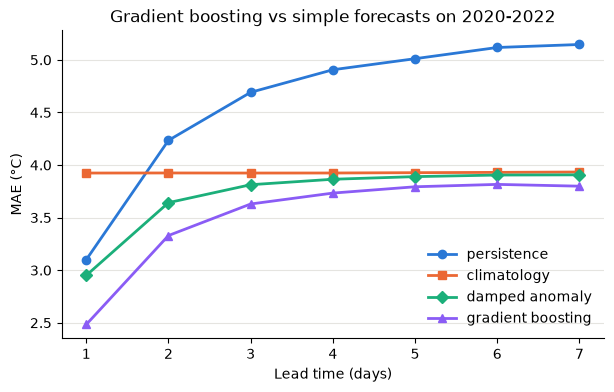

In [10]:
# Categorical slots 1-4 of the validated default palette; markers differ so identity is not color alone.
styles = {"persistence": ("#2a78d6", "o"), "climatology": ("#eb6834", "s"),
          "damped anomaly": ("#1baf7a", "D"), "gradient boosting": ("#8a5cf5", "^")}

fig, ax = plt.subplots(figsize=(7, 4))
for name, (color, marker) in styles.items():
    ax.plot(mae.index, mae[name], color=color, marker=marker, markersize=6, linewidth=2, label=name)
ax.set(xlabel="Lead time (days)", ylabel="MAE (°C)", title="Gradient boosting vs simple forecasts on 2020-2022", xticks=list(mae.index))
ax.grid(axis="y", color="#e5e4e0")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower right")
plt.show()

## Check: why there is no day-of-year feature

Trains lead 4 twice with the untuned settings, with and without the day of year, and compares training and validation RMSE. A model that gets better on training years but worse on validation years is memorizing, not learning.

In [11]:
h, ahead = 4, pd.Timedelta(days=4)
y_train = train[f"y{h}"] - usual(train.STATION, train.DATE + ahead)
y_val = rows[f"y{h}"] - usual(rows.STATION, rows.DATE + ahead)
X4 = X.assign(clim_target=usual(data.STATION[keep], data.DATE[keep] + ahead))  # the lead 4 model's features
day = 2 * np.pi * data.DATE[keep].dt.day_of_year / 365.25
with_day = X4.assign(doy_sin=np.sin(day), doy_cos=np.cos(day))
check = {}
for name, features in {"without day of year": X4, "with day of year": with_day}.items():
    model = HistGradientBoostingRegressor(max_iter=300, early_stopping=False, random_state=0)
    model.fit(features[is_train], y_train)
    rmse_of = lambda pred, y: np.sqrt(((pred - y) ** 2).mean())
    check[name] = {"train RMSE": rmse_of(model.predict(features[is_train]), y_train),
                   "validation RMSE": rmse_of(model.predict(features[~is_train]), y_val)}
pd.DataFrame(check).T.round(2)

,train RMSE,validation RMSE
without day of year,4.10,5.17
with day of year,3.83,5.29


## Takeaways

* **Tuning:** the biggest gain came from switching the loss to absolute error, which predicts the median and so targets MAE directly (mean MAE at leads 1 and 7: 3.21 to 3.16 °C). A lower learning rate (0.05) and trying 60% of the features at each split took it to 3.14 °C. Leaf size, L2 penalty and more trees did not help. Like the random forest, the setting was picked on the validation years it is scored on, so these numbers are slightly optimistic. The test years are untouched.
* **Accuracy:** tuned gradient boosting beats damped anomaly at every lead (0.47 °C lower MAE at lead 1, about 0.1 °C at leads 5 to 7), and the luck test agrees at every lead. Its RMSE is lower at leads 1 to 4 but slightly worse at leads 5 to 7: the absolute-error loss shrinks typical errors, not the large ones.
* **Vs random forest:** MAE is 0.04 to 0.09 °C lower at every lead, and RMSE is within 0.03 °C. This gap is not luck-tested. Part of the gap is the loss, since the random forest minimizes squared error.
* **Day of year:** adding it makes training error drop (RMSE 4.10 to 3.83 °C) and validation error rise (5.17 to 5.29 °C): the trees memorize past dates.
* **Next:** the tier comparison (nearest stations, then west and north, then statewide), then score the test years.